##**1. All Imports**

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, f1_score, accuracy_score,
                              roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

sns.set_style('whitegrid')


In [9]:
df = pd.read_csv("Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")
df.columns = df.columns.str.strip()   # CICIDS column names have leading spaces
print(df.shape)
df.head()


(73929, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN


In [10]:
print(df['Label'].value_counts())
print("\nTotal columns:", df.shape[1])
print("Dtypes:\n", df.dtypes.value_counts())


Label
DDoS      40337
BENIGN    33591
Name: count, dtype: int64

Total columns: 79
Dtypes:
 float64    52
int64      26
object      1
Name: count, dtype: int64


In [11]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

num_cols = df.select_dtypes(include=[np.number]).columns
inf_counts = np.isinf(df[num_cols]).sum()
print("\nColumns with infinite values:\n", inf_counts[inf_counts > 0])

df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)
print("\nNaNs before drop:", df.isnull().sum().sum())
df = df.dropna()
print("Shape after cleaning:", df.shape)

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("\nConstant columns (to drop):", constant_cols)
df = df.drop(columns=constant_cols)
print("Shape after dropping constant columns:", df.shape)


Duplicate rows: 622

Columns with infinite values:
 Flow Bytes/s      12
Flow Packets/s    15
dtype: int64

NaNs before drop: 68
Shape after cleaning: (73291, 79)

Constant columns (to drop): ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Shape after dropping constant columns: (73291, 69)


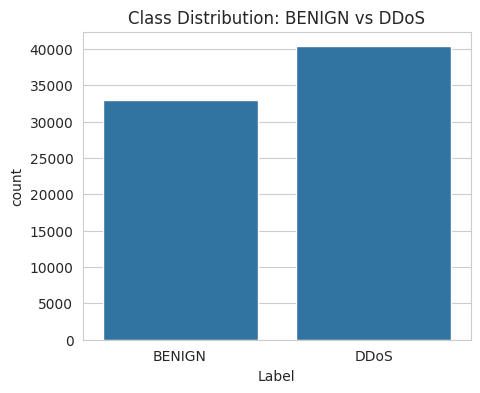

Label
DDoS      0.55034
BENIGN    0.44966
Name: proportion, dtype: float64


In [12]:
plt.figure(figsize=(5,4))
sns.countplot(data=df, x='Label')
plt.title('Class Distribution: BENIGN vs DDoS')
plt.show()
print(df['Label'].value_counts(normalize=True))


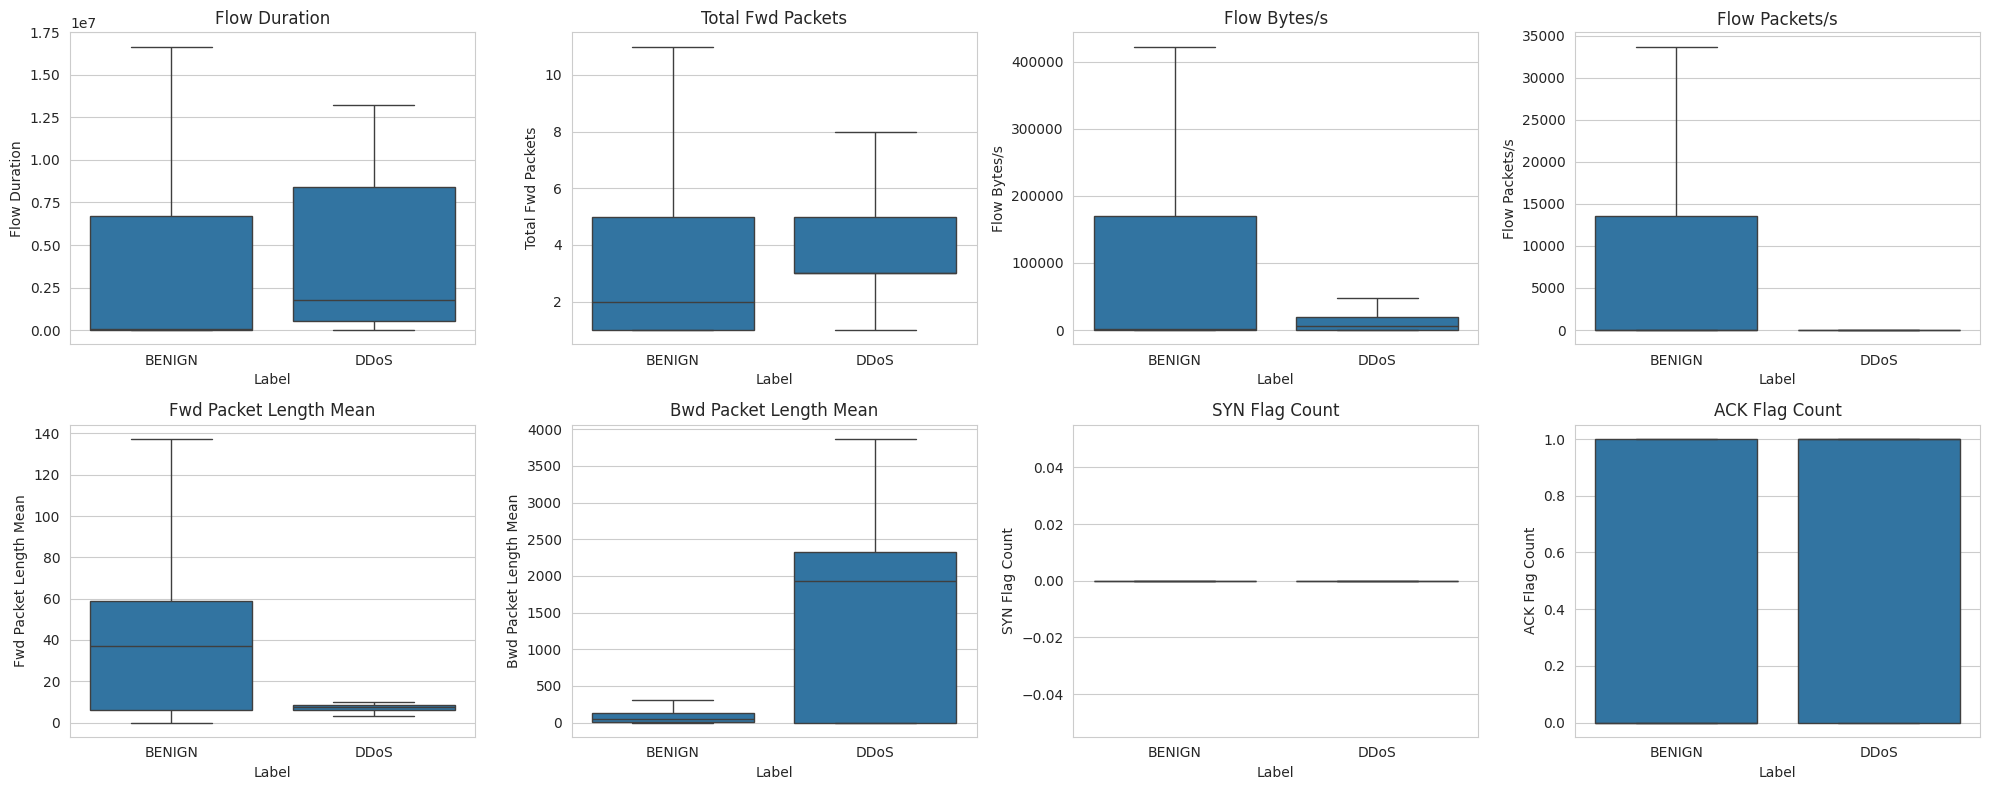

        Flow Duration  Total Fwd Packets  Flow Bytes/s  Flow Packets/s  \
Label                                                                    
BENIGN   1.466782e+07           6.020967  1.564553e+06    34195.697302   
DDoS     1.422124e+07           4.326714  6.598615e+04      175.189456   

        Fwd Packet Length Mean  Bwd Packet Length Mean  SYN Flag Count  \
Label                                                                    
BENIGN              251.989976              148.220591        0.072521   
DDoS                  7.509902             1539.481467        0.000000   

        ACK Flag Count  
Label                   
BENIGN        0.424111  
DDoS          0.500335  


In [13]:
key_features = ['Flow Duration', 'Total Fwd Packets', 'Flow Bytes/s', 'Flow Packets/s',
                 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'SYN Flag Count', 'ACK Flag Count']

fig, axes = plt.subplots(2, 4, figsize=(20,8))
for ax, col in zip(axes.flatten(), key_features):
    sns.boxplot(data=df, x='Label', y=col, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print(df.groupby('Label')[key_features].mean())


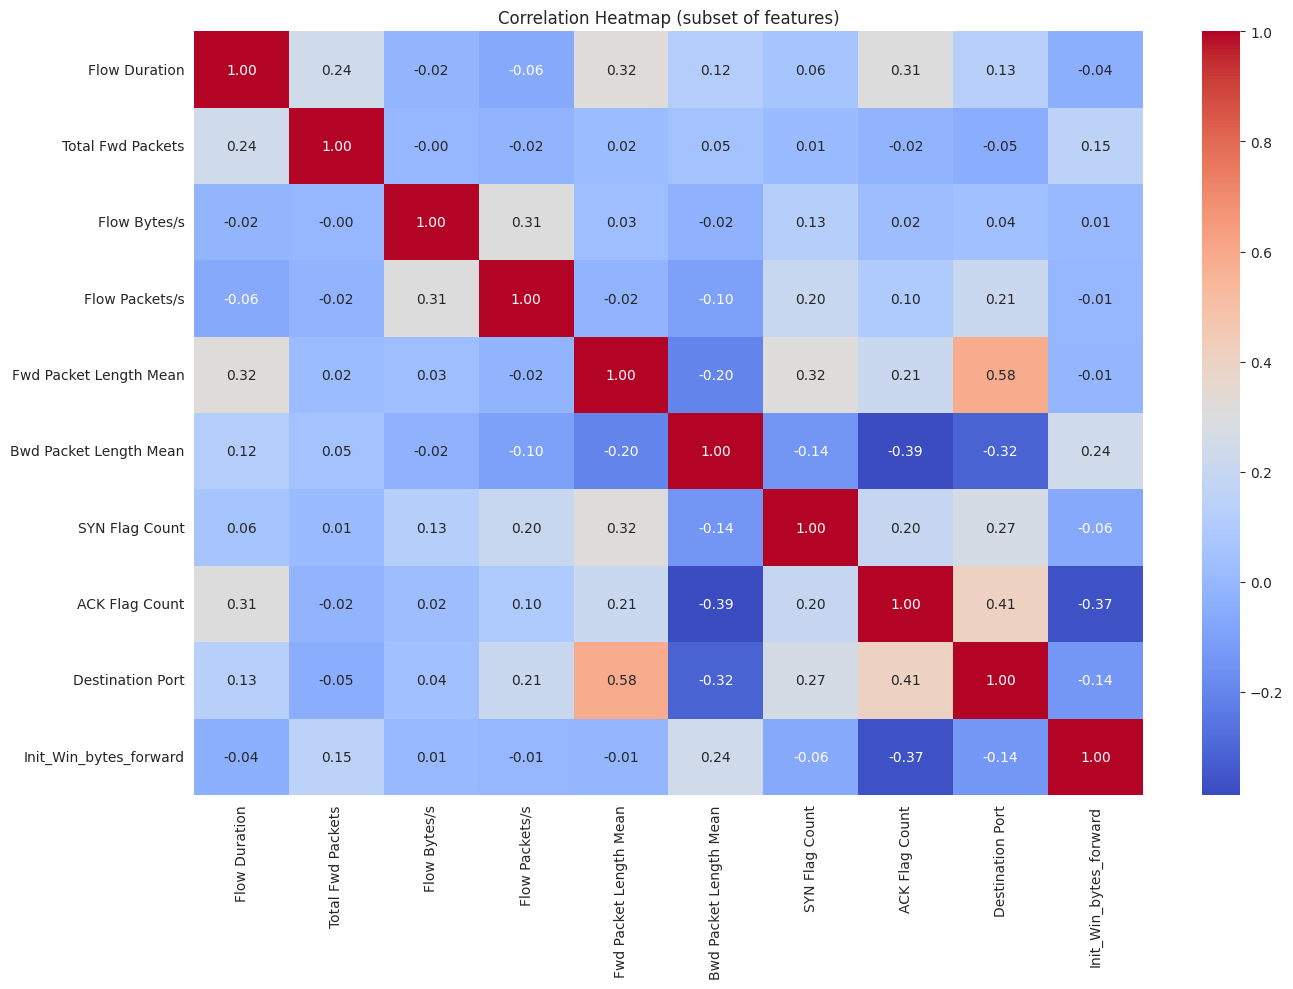

In [14]:
plt.figure(figsize=(14,10))
corr_features = key_features + ['Destination Port', 'Init_Win_bytes_forward']
corr = df[corr_features].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap (subset of features)')
plt.tight_layout()
plt.show()


In [15]:
y = (df['Label'] == 'DDoS').astype(int)   # 1 = DDoS, 0 = BENIGN
X = df.drop(columns=['Label'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (58632, 68)  Test shape: (14659, 68)


In [16]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)
pred_lr = lr.predict(X_test_scaled)
prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, pred_lr))
print("F1:", f1_score(y_test, pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, prob_lr))
print()
print(classification_report(y_test, pred_lr, target_names=['BENIGN', 'DDoS']))


Accuracy: 0.9977488232485162
F1: 0.997957541622826
ROC-AUC: 0.9997712385410535

              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00      6592
        DDoS       1.00      1.00      1.00      8067

    accuracy                           1.00     14659
   macro avg       1.00      1.00      1.00     14659
weighted avg       1.00      1.00      1.00     14659



In [17]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
prob_rf = rf.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, pred_rf))
print("F1:", f1_score(y_test, pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, prob_rf))
print()
print(classification_report(y_test, pred_rf, target_names=['BENIGN', 'DDoS']))


Accuracy: 0.9998635650453647
F1: 0.9998760228118027
ROC-AUC: 0.9999996427071336

              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00      6592
        DDoS       1.00      1.00      1.00      8067

    accuracy                           1.00     14659
   macro avg       1.00      1.00      1.00     14659
weighted avg       1.00      1.00      1.00     14659



## 9. Model Comparison

                 Model  Accuracy  F1-score   ROC-AUC
0  Logistic Regression  0.997749  0.997958  0.999771
1        Random Forest  0.999864  0.999876  1.000000


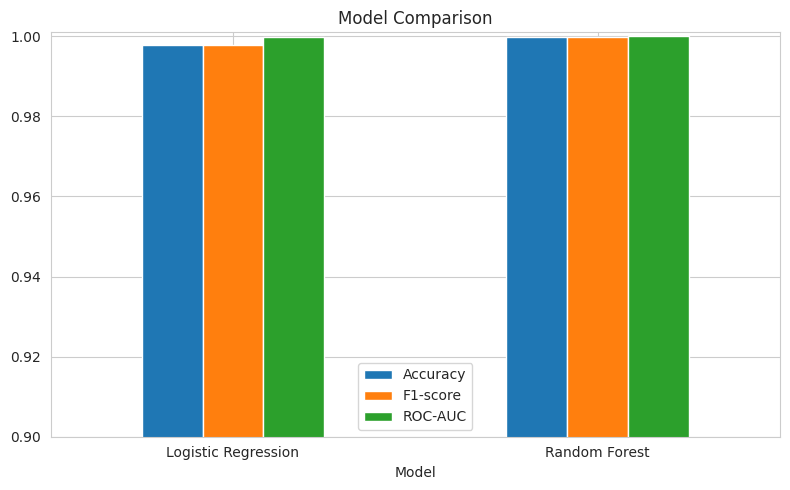

In [18]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, pred_lr), accuracy_score(y_test, pred_rf)],
    'F1-score': [f1_score(y_test, pred_lr), f1_score(y_test, pred_rf)],
    'ROC-AUC': [roc_auc_score(y_test, prob_lr), roc_auc_score(y_test, prob_rf)]
})
print(results)

results.set_index('Model')[['Accuracy', 'F1-score', 'ROC-AUC']].plot(kind='bar', figsize=(8,5), ylim=(0.9,1.001))
plt.title('Model Comparison')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


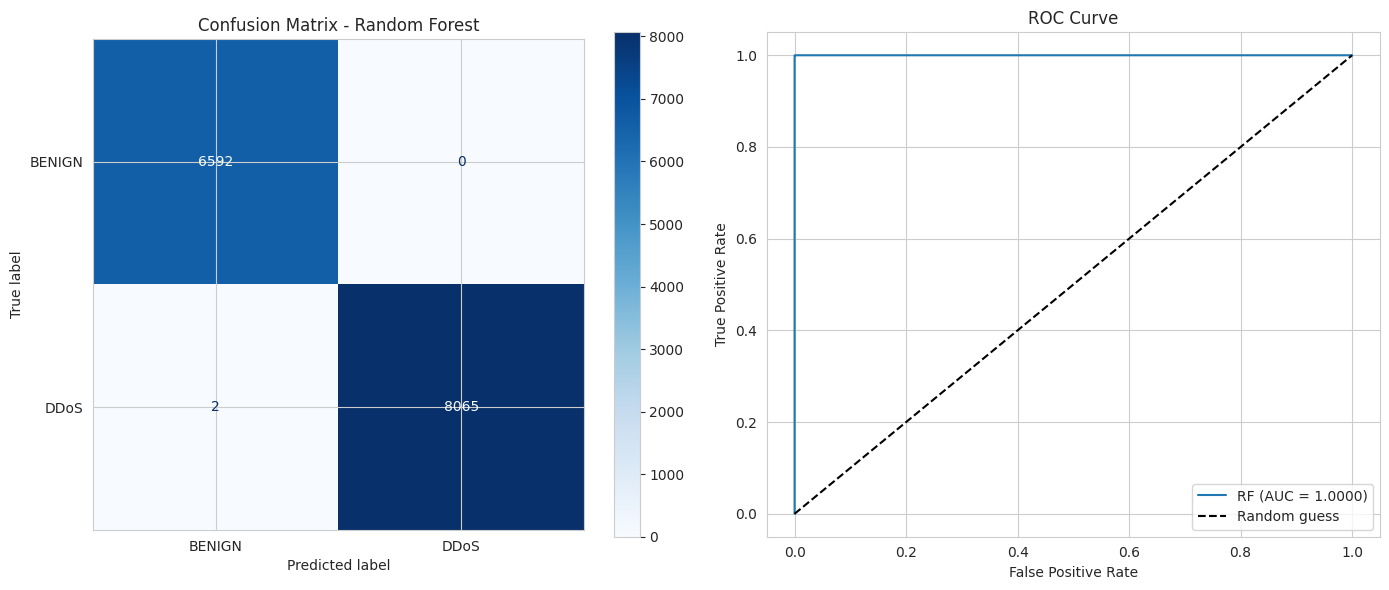

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14,6))

cm = confusion_matrix(y_test, pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['BENIGN', 'DDoS'])
disp.plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Confusion Matrix - Random Forest')

fpr, tpr, _ = roc_curve(y_test, prob_rf)
axes[1].plot(fpr, tpr, label=f'RF (AUC = {roc_auc_score(y_test, prob_rf):.4f})')
axes[1].plot([0,1],[0,1],'k--', label='Random guess')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()


/tmp/ipykernel_724/1981068223.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette='mako')


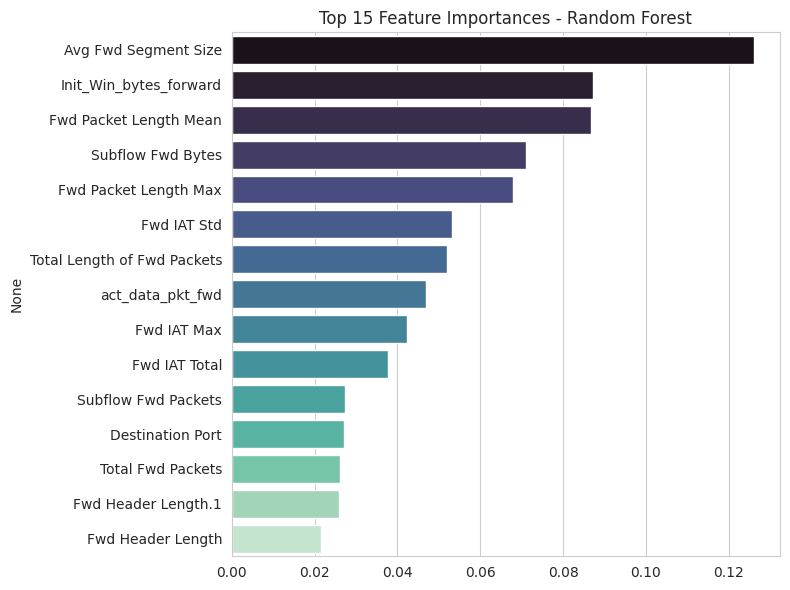

Avg Fwd Segment Size           0.126065
Init_Win_bytes_forward         0.087300
Fwd Packet Length Mean         0.086826
Subflow Fwd Bytes              0.071078
Fwd Packet Length Max          0.067829
Fwd IAT Std                    0.053243
Total Length of Fwd Packets    0.051861
act_data_pkt_fwd               0.047000
Fwd IAT Max                    0.042239
Fwd IAT Total                  0.037836
Subflow Fwd Packets            0.027251
Destination Port               0.027126
Total Fwd Packets              0.026011
Fwd Header Length.1            0.025924
Fwd Header Length              0.021604
dtype: float64


In [20]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x=importances.head(15).values, y=importances.head(15).index, palette='mako')
plt.title('Top 15 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()

print(importances.head(15))


In [24]:
train_acc_lr = accuracy_score(y_train, lr.predict(X_train_scaled))
test_acc_lr = accuracy_score(y_test, pred_lr)

train_acc_rf = accuracy_score(y_train, rf.predict(X_train))
test_acc_rf = accuracy_score(y_test, pred_rf)
overfit_check=pd.DataFrame({'Model': ['Logistic Regression', 'Random Forest'],
    'Train Accuracy': [train_acc_lr, train_acc_rf],
    'Test Accuracy': [test_acc_lr, test_acc_rf],
    'Gap (Train - Test)': [train_acc_lr - test_acc_lr, train_acc_rf - test_acc_rf]
})
print(overfit_check)

                 Model  Train Accuracy  Test Accuracy  Gap (Train - Test)
0  Logistic Regression         0.99826       0.997749            0.000512
1        Random Forest         1.00000       0.999864            0.000136


In [25]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Logistic Regression CV (on scaled full data)
X_scaled_full = scaler.fit_transform(X)
cv_scores_lr = cross_val_score(lr, X_scaled_full, y, cv=cv, scoring='f1', n_jobs=-1)

# Random Forest CV (on unscaled full data)
cv_scores_rf = cross_val_score(rf, X, y, cv=cv, scoring='f1', n_jobs=-1)

print("Logistic Regression CV F1 scores:", cv_scores_lr)
print("Mean F1:", cv_scores_lr.mean(), " Std:", cv_scores_lr.std())
print()
print("Random Forest CV F1 scores:", cv_scores_rf)
print("Mean F1:", cv_scores_rf.mean(), " Std:", cv_scores_rf.std())

Logistic Regression CV F1 scores: [0.9986376  0.99801931 0.99826625 0.99795653 0.99857541]
Mean F1: 0.9982910215840946  Std: 0.0002783233780088205

Random Forest CV F1 scores: [0.99975205 1.         0.99987602 0.99975208 0.99975205]
Mean F1: 0.9998264380838989  Std: 9.917714068142685e-05
